In [1]:
import sys
import os
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt

#import pynwb
import h5py

from sklearn.decomposition import PCA


sys.path.append(os.path.join(os.getcwd(), '../import'))

# noinspection PyUnresolvedReferences
from utils import read_utils

In [3]:
path = os.path.join(os.path.expanduser('~'), 'Desktop/DATA/fly-2023-schaffner')			# path to nbw file folder
# file_ids, filenames, traces, ball_motions, behavioral_states = read_utils.get_data(path)

In [9]:
def print_structure(name, _):
	print(name)

raw_files = read_utils.get_hdf5_files(path, file_ids)
for raw_file in raw_files:
	print('================ FILENAME', raw_file.filename)
	raw_file.visititems(print_structure)

================ FILENAME /home/julian-zim/Desktop/DATA/fly-2023-schaffner/2018_08_24_fly2_run2.nwb
acquisition
analysis
file_create_date
general
general/devices
general/devices/Device
general/experiment_description
general/experimenter
general/institution
general/lab
general/optophysiology
general/optophysiology/ImagingPlane
general/optophysiology/ImagingPlane/OpticalChannel
general/optophysiology/ImagingPlane/OpticalChannel/description
general/optophysiology/ImagingPlane/OpticalChannel/emission_lambda
general/optophysiology/ImagingPlane/description
general/optophysiology/ImagingPlane/excitation_lambda
general/optophysiology/ImagingPlane/imaging_rate
general/optophysiology/ImagingPlane/indicator
general/optophysiology/ImagingPlane/location
general/session_id
identifier
intervals
intervals/trials
intervals/trials/id
intervals/trials/start_time
intervals/trials/stop_time
processing
processing/behavior
processing/behavior/ball_motion
processing/behavior/ball_motion/data
processing/behavi

In [15]:
print(hdf5file.filename.split('/')[-1].split('.')[0])

2019_04_18_fly2


acquisition
analysis
file_create_date
general
general/devices
general/devices/Device
general/experiment_description
general/experimenter
general/institution
general/lab
general/optophysiology
general/optophysiology/ImagingPlane
general/optophysiology/ImagingPlane/OpticalChannel
general/optophysiology/ImagingPlane/OpticalChannel/description
general/optophysiology/ImagingPlane/OpticalChannel/emission_lambda
general/optophysiology/ImagingPlane/description
general/optophysiology/ImagingPlane/excitation_lambda
general/optophysiology/ImagingPlane/imaging_rate
general/optophysiology/ImagingPlane/indicator
general/optophysiology/ImagingPlane/location
general/session_id
identifier
intervals
intervals/trials
intervals/trials/id
intervals/trials/start_time
intervals/trials/stop_time
processing
processing/behavior
processing/behavior/ball_motion
processing/behavior/ball_motion/data
processing/behavior/ball_motion/timestamps
processing/behavioral state
processing/behavioral state/behavioral state
p

In [17]:
hdf5file['processing'].visititems(print_structure)

behavior
behavior/ball_motion
behavior/ball_motion/data
behavior/ball_motion/timestamps
behavioral state
behavioral state/behavioral state
behavioral state/behavioral state/data
behavioral state/behavioral state/timestamps
ophys
ophys/DfOverF
ophys/DfOverF/RoiResponseSeries
ophys/DfOverF/RoiResponseSeries/data
ophys/DfOverF/RoiResponseSeries/rois
ophys/DfOverF/RoiResponseSeries/timestamps
ophys/GrayscaleVolume
ophys/GrayscaleVolume/data
ophys/ImageSegmentation
ophys/ImageSegmentation/ImagingPlane
ophys/ImageSegmentation/ImagingPlane/id
ophys/ImageSegmentation/ImagingPlane/reference_images
ophys/ImageSegmentation/ImagingPlane/voxel_mask
ophys/ImageSegmentation/ImagingPlane/voxel_mask_index


In [24]:
def get_neuronal_traces(file_handle):
	data = pd.DataFrame(file_handle[f'/processing/ophys/DfOverF/RoiResponseSeries/data'][:])
	try:
		data.columns = [str(n_id) for n_id in file_handle[f'/processing/ophys/DfOverF/RoiResponseSeries/rois'][:]]
	except ValueError:
		data.columns = ['?' for _ in range(data.shape[1])]
	return data


def get_ball_motions(file_handle):
	return pd.DataFrame(file_handle[f'/processing/behavior/ball_motion/data'][:],
						columns=['?'])


def get_behavioral_states(file_handle):
	data = pd.DataFrame(file_handle[f'/processing/behavioral state/behavioral state/data'][:].round(0).astype(int))
	try:
		data.columns = ['undefined', 'quiescence', 'ab_bending', 'grooming_b', 'grooming_f', 'running']
	except ValueError:
		data.columns = ['?']
	return data

In [25]:
traces = get_neuronal_traces(hdf5file)
behavioral_states = get_behavioral_states(hdf5file)
ball_motions = get_ball_motions(hdf5file)

Text(0.5, 1.025, '2019_04_18_fly2.nwb')

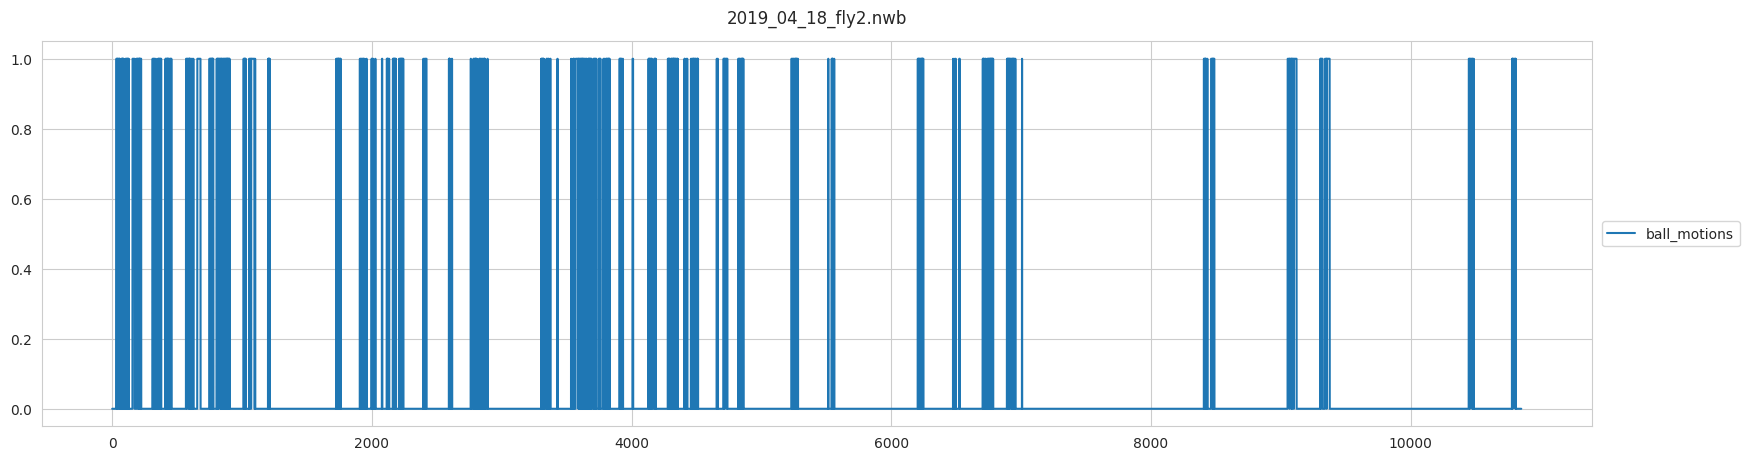

In [26]:
x = np.arange(len(ball_motions))

plt.figure(figsize=(20, 5))
plt.plot(x, ball_motions, label='ball_motions')
# plt.plot(x, reversals, label='Reversals')
plt.legend(loc='center right', bbox_to_anchor=(1.1, 0.5))
plt.title(f'{os.path.basename(hdf5file.filename)}', y=1.025, fontsize=12)

# corr = np.corrcoef(velocity, reversals)
# print(corr)

### reproducing trace from figure 7 b fly 2

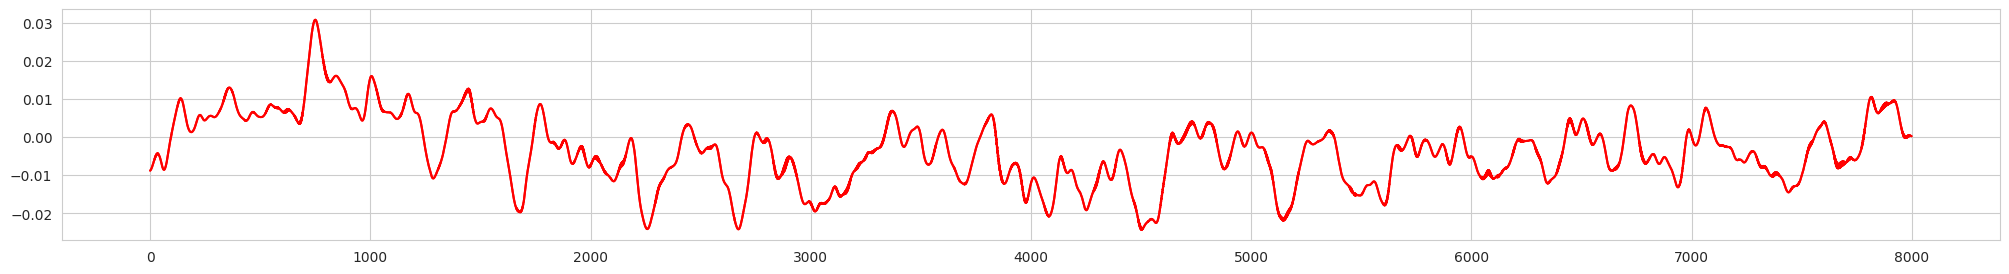

In [29]:
with h5py.File(os.path.join(path, '2022_01_08_fly2.nwb'), "r") as f:
	t = f['processing/ophys/DfOverF/RoiResponseSeries/data'][:]
	plt.figure(figsize=(25, 3))
	plt.plot(t[:8000], color='red')